**ANN for Concrete Strength Prediction**

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/seting_kfold_1.txt
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_3.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/seting_kfold_2.txt
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/w_kfold_0.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_2.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/w_kfold_1.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_9.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_8.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/w_kfold_2.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_4.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_1.npy
/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/w_kfold_5.npy
/kaggle/input/data

In [2]:
import warnings
from sklearn.exceptions import InconsistentVersionWarning

# Filtre pour ignorer spécifiquement cette alerte de version
warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
warnings.filterwarnings("ignore", message="X does not have valid feature names")

In [3]:
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import PowerTransformer
import joblib
import linecache
import math
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import KFold, StratifiedKFold
import matplotlib.pyplot as plt

In [4]:
def normalization(param, n_splits):
    for K_FOLD_count in range(0, n_splits):
        # Lecture des données brutes de test de la compétition
        df = pd.read_csv("/kaggle/input/competitions/concrete-strength-regression/test.csv")
        
        # CHEMIN MODIFIÉ : Pointe vers le nouveau scaler généré par le Notebook 2
        filename = f'/kaggle/input/datasets/noureddinebelmokhtar/scaler-cs-9-imput-v5/scale_features_{K_FOLD_count}.joblib'
        txt_fil = f"/kaggle/working/df_{param}_features_{K_FOLD_count}.csv"
    
        # Ingénierie des caractéristiques (identique à l'entraînement)
        eps = 1e-6
       
        df['w_b_ratio'] = df['water'] / (df['cement'] + df['slag'] + df['flyash'] + eps)
        df['log_age'] = np.log1p(df['age'])
        df['cement_age'] = df['cement'] * df['log_age']
        df['binder_richness'] = (df['cement'] + df['slag'] + df['flyash']) / (df['fineaggregate'] + df['coarseaggregate'] + eps)
        
        # Suppression de la colonne age d'origine
        df = df.drop(columns=['age'])
        
        # Isolation des caractéristiques et de l'ID de ligne
        X_test = df.drop(columns=['Row ID'])
        id_ = df[['Row ID']]
    
        # Chargement du scaler PowerTransformer Yeo-Johnson
        loaded_scaler = joblib.load(filename)
        
        # Transformation des données de test
        X_test_scaled = loaded_scaler.transform(X_test)
        
        # Reconversion en DataFrame en conservant l'ordre des colonnes d'origine
        X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)
    
        # CORRECTION CRUCIALE : Ajout de index=False pour éviter l'insertion de l'index dans le CSV
        X_test_scaled.to_csv(txt_fil, index=False)
        print(f"saved; path : {txt_fil}")

    return id_

param =  'csMPa'
n_splits = 10
id_ = normalization(param, n_splits)

saved; path : /kaggle/working/df_csMPa_features_0.csv
saved; path : /kaggle/working/df_csMPa_features_1.csv
saved; path : /kaggle/working/df_csMPa_features_2.csv
saved; path : /kaggle/working/df_csMPa_features_3.csv
saved; path : /kaggle/working/df_csMPa_features_4.csv
saved; path : /kaggle/working/df_csMPa_features_5.csv
saved; path : /kaggle/working/df_csMPa_features_6.csv
saved; path : /kaggle/working/df_csMPa_features_7.csv
saved; path : /kaggle/working/df_csMPa_features_8.csv
saved; path : /kaggle/working/df_csMPa_features_9.csv


In [5]:
 #train_data = pd.read_csv("/kaggle/input/datasets/noureddinebelmokhtar/scaled-data/train_df__scaled.csv")
 #test_data = pd.read_csv("/kaggle/input/datasets/noureddinebelmokhtar/scaled-data/test_df__scaled.csv")

In [6]:
def elu(n1, alpha=1.0):
    # np.where applique la condition élément par élément sur tout le tableau n1
    return np.where(n1 > 0, n1, alpha * (np.exp(n1) - 1.0))

def swish(n1):
    # Version robuste utilisant la fonction sigmoid(n1) déjà définie
    return n1 * sigmoid(n1)

ALPHA = 1.67326
SCALE = 1.05070

def selu(n1):
    # np.where applique la condition et les calculs sur chaque élément du tableau
    return np.where(n1 > 0, SCALE * n1, SCALE * ALPHA * (np.exp(n1) - 1.0))

# --- 1. SIGMOID ---
def sigmoid(n1):
    # np.clip empêche les valeurs trop extrêmes d'engendrer un débordement d'exponentielle (Overflow)
    #n1_clipped = np.clip(n1, -500, 500)
    return 1.0 / (1.0 + np.exp(-n1))

def tanh(n1):
    return np.tanh(n1)

def relu(n1):
    return np.maximum(0, n1)

def linear(n1):
    return n1

ALPHA = 0.01

def leaky_relu(n1):
    # Si n1 > 0, on garde n1. Sinon, on applique la pente ALPHA.
    return np.where(n1 > 0, n1, ALPHA * n1)

def neuron(type_fonc, n1):
    try:
        if type_fonc == 0:  #sigmoid
            a = sigmoid(n1)
            
        elif type_fonc == 1:   #identity
            a = linear(n1)
            
        elif type_fonc == 2:  #tanh
            a = tanh(n1)
            
        elif type_fonc == 3:  #relu
            a = relu(n1)
                
        elif type_fonc == 4:  #leaky_relu
            a = leaky_relu(n1)
        
        elif type_fonc == 5:  #elu
            a = elu(n1, alpha=1.0)
            
        elif type_fonc == 6:  #swish
            a = swish(n1)
            
        elif type_fonc == 7:  #selu
            a = selu(n1)
    except OverflowError:
        a = float('inf')

    return (a)



In [7]:
def get_kfold_datasets(df, n_splits=10, stratify=True, target_col='csMPa'):
    # On vérifie si la colonne existe
    if target_col not in df.columns:
        target_values = df.iloc[:, -1] 
    else:
        target_values = df[target_col]

    if stratify:
        y_bins = pd.qcut(target_values, q=5, labels=False, duplicates='drop')
        kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        indices = kf.split(df, y_bins)
    else:
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
        indices = kf.split(df)

    for train_idx, val_idx in indices:
        # CORRECTION : On renvoie les DEUX datasets séparés par une virgule
        yield df.iloc[train_idx].reset_index(drop=True), df.iloc[val_idx].reset_index(drop=True) 

In [8]:
class ReseauUnifie:
    def __init__(self, n_neron):
        self.n_neron = n_neron
        
        # 1. Calcul de la taille totale du buffer
        total_size = 0
        for i in range(len(n_neron)-1):
            total_size += n_neron[i] * n_neron[i+1] 
            total_size += n_neron[i+1]  # Biai
            
        # 2. Création du Buffer unique
        self.params = np.zeros(total_size, dtype=np.float32)
        self.params01 = np.zeros(total_size, dtype=np.float32)
       
        
        # 3. Création des "Views"
        self.layers_w = []
        self.layers_b = []
        self.layers_w01 = []
        self.layers_dw = []

        current_idx = 0
       
        for i in range(len(n_neron)-1):
            
            w_size = n_neron[i] * n_neron[i+1]
            w_view = self.params[current_idx : current_idx + w_size].reshape(n_neron[i], n_neron[i+1])
            self.layers_w.append(w_view)
         
            w01_view = self.params01[current_idx : current_idx + w_size].reshape(n_neron[i], n_neron[i+1])
            self.layers_w01.append(w01_view)
            
          
            current_idx += w_size
            
            
            b_size = n_neron[i+1]
            b_view = self.params[current_idx : current_idx + b_size]
            self.layers_b.append(b_view)
            
           
            current_idx += b_size

In [9]:
def list_predict_original(sortie_finale, df_array_Y): 

     # 1. Soustraction globale
     diff = sortie_finale - df_array_Y
     
     # 2. Somme de la différence sur toutes les lignes pour chaque colonne (axe 0)
     somme_colonnes = np.sum(diff, axis=0)
     
     # 3. Trouver l'index de la meilleure colonne unique
     meilleure_colonne = np.argmax(somme_colonnes)
    
     # 4. Extraction directe de cette colonne (taille n, 1)
     sortie_finale_mono = sortie_finale[:, meilleure_colonne].reshape(-1, 1)
     Y_batch_mono = df_array_Y[:, meilleure_colonne].reshape(-1, 1)
    
     predict_list = sortie_finale_mono.flatten().tolist()
     origine_list = Y_batch_mono.flatten().tolist()
     
     return predict_list, origine_list
     

In [10]:
def blocs_f(n_neron_i, data_kind):
    x = n_neron_i
    y = data_kind
    z=round(x/y,0)
    blocs = []
    m = x
    for i in range(y):
        

        if i != y -1:
            blocs.append(int(z))
        
        if i == y -1:
            blocs.append(int(m))
        m = x - z
        x = m
    return blocs


val dataset :
MSE error: 18.15202048851844
RMSE = 4.2605
MAE = 3.0566
R² = 0.9385


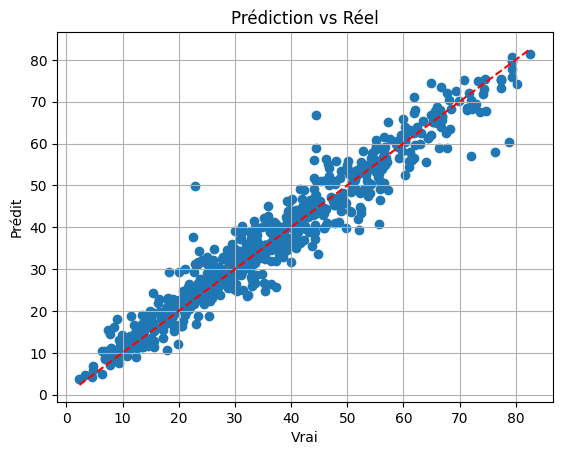

    predict0   predict1   predict2   predict3   predict4   predict5  \
0  28.747032  35.005895  33.639214  30.991165  32.538038  34.004143   
1  32.952281  27.390088  28.995833  30.647226  31.986831  34.947568   
2  23.231513  23.752100  24.032685  23.005131  24.641575  23.554511   
3  58.195928  60.148751  59.166406  61.075578  63.195999  63.790540   
4  49.083888  46.402825  44.578775  45.388111  45.240514  48.058956   

    predict6   predict7   predict8   predict9    moyenne  
0  32.701564  32.303961  32.268282  26.545865  31.874516  
1  29.950566  30.363163  29.826745  29.085294  30.614559  
2  23.558320  24.151902  22.522909  21.147701  23.359835  
3  61.538746  59.300362  57.824260  61.764072  60.600064  
4  48.174066  43.113481  44.661869  44.748843  45.945133  


In [11]:
def valid(test_fill, param, t_v_t, n_splits):
    if n_splits > 1 :
        if t_v_t == "val" or t_v_t == "train":
            df = pd.read_csv(test_fill, sep=',', skiprows=1, header=None)
            fold_generator = get_kfold_datasets(df, n_splits=n_splits, stratify=True)
        K_FOLD_count = 0
    nn_fille_2=test_fill
    prediction = []
    origine_list = []
    for k_fold_i in range(0, n_splits):
       
        if n_splits > 1:
            if t_v_t == "test":
                nn_fille_2 = f"{test_fill}_{K_FOLD_count}.csv"
            if t_v_t == "val":
                train_set, val_set = next(fold_generator)
                val_set.to_csv('/kaggle/working/val_set.csv', index=False)
                #nn_fille_2 = '/kaggle/working/val_set.csv'
                nn_fille_2 = f'/kaggle/input/datasets/noureddinebelmokhtar/scaled-data-v5/val_fold_{K_FOLD_count}_scaled.csv'

            seting_path = f"/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/seting_kfold_{K_FOLD_count}.txt"
            params_path = f"/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/w_kfold_{K_FOLD_count}.npy"
            params01_path = f"/kaggle/input/datasets/noureddinebelmokhtar/k-fold-ann-19-22-cs/01table_kfold_{K_FOLD_count}.npy"
            
        sub_prediction = []
        sub_origine_list = []
        final = 0
      
        if n_splits == 1:
            params01_path = f"/kaggle/input/datasets/noureddinebelmokhtar/model-cs-adamw/01table.npy"
            params_path = f"/kaggle/input/datasets/noureddinebelmokhtar/model-cs-adamw/w.npy"
            seting_path = f"/kaggle/input/datasets/noureddinebelmokhtar/model-cs-adamw/seting.txt"
        incrimente=0
        n_output_lear = 0
        k = 0
        j = 0
        i = 0
        
        var=0
        h_lears = None
        
        input_1 = 0
        outt = None
        n11=0
        type_f_a = []
        type_f_w_b = []
        n_neron = []
        
        #fichier1[0]=[]
        output_nerons_num=[]
        p=[]
        
        fichier1=[]
        fichier = open(seting_path, "r")
        fichier1=fichier.read().split()
        input_1 = int(fichier1[0])
        output = int(fichier1[1])
        h_lears = int(fichier1[2])
        n_output_lear=h_lears+1
        k = 3
        
        while k<3+h_lears+2:
            n_neron.append(int(fichier1[k]))
            k += 1
        data_kind = int(fichier1[k])
        k=k+1  #7
        output_nerons_num_size=int(fichier1[k])
        
        k=k+1
        
        for i in range(0,output_nerons_num_size):
            output_nerons_num.append(int(fichier1[k]))
           
            k += 1
        #n_neron.append(0)
        i=0
        p=[]
        #k=9
        n_type_f = int(fichier1[k])
        k += 1
        j = 0
        while j<data_kind:
            i = 0
            p=[]
            while i<n_type_f:
                p.append(int(fichier1[k]))
                i += 1
                k += 1
            p.append(p)
            p=[]
            j += 1
        j = 0
        while j<output_nerons_num_size:
            i = 0
            p=[]
            while i<n_type_f:
                p.append(int(fichier1[k]))
                i += 1
                k += 1
            p.append(p)
            p=[]
            j += 1
        pages = int(fichier1[k])
        rows = int(fichier1[k+1])
        colons = int(fichier1[k+2])
        x_factor = int(fichier1[k+3]) 
       
        k=k+3
        x_factor = int(fichier1[k+1])
        x_factor = int(fichier1[k+2])
        x_factor = int(fichier1[k+3])
        x_factor = int(fichier1[k+4])
        x_factor = (fichier1[k+5]) 
        x_factor = (fichier1[k+6]) 
        k=k+6
        x_factor = int(fichier1[k+1]) 
        x_factor = int(fichier1[k+2])
        x_factor = float(fichier1[k+3])
   
        x_factor = fichier1[k+4]
        
        x_factor = int(fichier1[k+5])
        x_factor = int(fichier1[k+6]) 
        x_factor = float(fichier1[k+7])
        x_factor = int(fichier1[k+8])
        k=k+9
        p=0
        pp=[]
        for p in range(0,h_lears):
            for i in range(0, data_kind):
                k+=1
                
        for p in range(0,output_nerons_num_size):
            k+=1
        
        for p in range(0,h_lears):
            for i in range(0, data_kind):
                pp.append(int(fichier1[k]))
                k+=1
            type_f_a.append(pp)
            pp=[]
            
        for p in range(0,output_nerons_num_size):
            pp.append(int(fichier1[k]))
            k+=1
        type_f_a.append(pp)
        p=[]
        fichier.close()

        Network = ReseauUnifie(n_neron)
        
        df = pd.read_csv(nn_fille_2, sep=',', skiprows=1, header=None)
        df_array = df.to_numpy()
        df_array_X = df_array[:, 0 : input_1]
        if t_v_t == 'train' or t_v_t == 'val':
            df_array_Y = df_array[:, input_1 :]
       
        activations = [df_array_X]
        
        Network.params[:] = np.load(params_path)
        
        Network.params01[:] = np.load(params01_path)
        
        for i in range(pages):
            kind_neron=0
            sweetch=0
            blocs = blocs_f(n_neron[i+1], data_kind)
            
            n = np.dot(activations[i], Network.layers_w[i] * Network.layers_w01[i]) + Network.layers_b[i]
          
            # Matrice d'activation vide pour la couche courante
            a = np.zeros_like(n)
            
            # On applique l'activation propre à chaque neurone j de la couche i
            for j in range(n_neron[i+1]):
                func = type_f_a[i][sweetch]
                a[:, j] = neuron(func, n[:, j])
                
                kind_neron= kind_neron + 1
                if i<pages-1:
                    if kind_neron== blocs[sweetch]:
                        sweetch= sweetch + 1
                        kind_neron=0
                if i==pages-1:
                    if kind_neron==output_nerons_num[sweetch]:
                        sweetch= sweetch + 1
                        kind_neron=0
            activations.append(a)
            
        sortie_finale = activations[-1]

        if t_v_t == 'train' or t_v_t == 'val':
            sub_prediction, sub_origine_list = list_predict_original(sortie_finale, df_array_Y)

        
        y_filename = f'/kaggle/input/datasets/noureddinebelmokhtar/scaler-cs-9-imput-v5/scale_target_{K_FOLD_count}.joblib'
        y_scaler = joblib.load(y_filename)

        
        if t_v_t != 'test':
            prediction_numpy = y_scaler.inverse_transform(np.array(sub_prediction).reshape(-1, 1))
            sub_prediction = prediction_numpy.flatten().tolist()
            
            origine_list_numpy = y_scaler.inverse_transform(np.array(sub_origine_list).reshape(-1, 1))
            sub_origine_list = origine_list_numpy.flatten().tolist()
        else:
            prediction_numpy = y_scaler.inverse_transform(np.array(sortie_finale).reshape(-1, 1))
            sub_prediction = prediction_numpy.flatten().tolist()

        # 4. Stockage des prédictions (déjà inversées par fold)
        if n_splits > 1 and t_v_t == 'test':
            if K_FOLD_count == 0:
                df_original_predictions = pd.DataFrame()
            df_original_predictions[f"predict{K_FOLD_count}"] = sub_prediction
            K_FOLD_count += 1
            
        elif n_splits > 1 and (t_v_t == 'val' or t_v_t == 'train'):
            prediction.extend(sub_prediction)
            origine_list.extend(sub_origine_list)
            K_FOLD_count += 1
            
        elif n_splits == 1:
            prediction = sub_prediction
            origine_list = sub_origine_list
            
    if n_splits > 1 and t_v_t == 'test':
        df_original_predictions['moyenne'] = df_original_predictions.mean(axis=1)
        prediction = df_original_predictions['moyenne'].tolist()
        print(df_original_predictions.head(5))
 
    return prediction, origine_list
    
prediction = []
train_val_test =["train", "val", "test"]
for t_v_t in train_val_test:    
    param =  'csMPa'
  
    if t_v_t == "train" and n_splits == 1:
        test_fill = "/kaggle/input/datasets/noureddinebelmokhtar/scaled-data/train_fold_0_scaled.csv"
        prediction, origine_list = valid(test_fill, param, t_v_t, n_splits)
    elif t_v_t == "val":
        test_fill = "/kaggle/input/datasets/noureddinebelmokhtar/scaled-data-v5/train_fold_0_scaled.csv"
        prediction, origine_list = valid(test_fill, param, t_v_t, n_splits)
    elif t_v_t == "test":
        if n_splits == 1:
            test_fill = f"/kaggle/working/df_{param}_features.csv"
        else:
            test_fill= f"/kaggle/working/df_{param}_features"
        prediction, origine_list = valid(test_fill, param, t_v_t, n_splits)
        
    
    
    if t_v_t == "val" or  t_v_t == "train" and n_splits == 1:
        print(f"{t_v_t} dataset :")
        mse = mean_squared_error(origine_list, prediction)       
        print(f"MSE error: {mse}")
        rmse = np.sqrt(mean_squared_error(origine_list, prediction))
        print(f"RMSE = {rmse:.4f}")
        mae = mean_absolute_error(origine_list, prediction)
        print(f"MAE = {mae:.4f}")
        r2 = r2_score(origine_list, prediction)
        print(f"R² = {r2:.4f}")
        plt.scatter(origine_list, prediction)
        plt.plot([min(origine_list), max(origine_list)], [min(origine_list), max(origine_list)], 'r--')  # diagonale idéale
        plt.xlabel("Vrai")
        plt.ylabel("Prédit")
        plt.title("Prédiction vs Réel")
        plt.grid()
        plt.show()

4. Performance Analysis

5. Conclusion
By developing a system that generates its own weights, biases, and connectivity tables, this project provides a unique tool for materials R&D. The ability to visualize and export the connectivity as a raw binary table (01table.txt) allows for a level of transparency and structural optimization rarely found in standard machine learning workflows.

In [12]:
prediction = pd.DataFrame({param : prediction})
test_df = pd.concat([id_, prediction], axis=1)
test_df.to_csv("/kaggle/working/submission.csv", index=False)
print(test_df)

     Row ID      csMPa
0       721  31.874516
1       722  30.614559
2       723  23.359835
3       724  60.600064
4       725  45.945133
..      ...        ...
304    1025  63.953626
305    1026  40.102070
306    1027  30.559298
307    1028  35.401471
308    1029  56.540130

[309 rows x 2 columns]


In [13]:
import pandas as pd
loaded_paths = pd.DataFrame(data=["No thing"])
print(loaded_paths)

          0
0  No thing
